In [1]:
from google.colab import files
uploaded = files.upload()

Saving merged_dataset.csv to merged_dataset.csv


In [2]:
import pandas as pd
import numpy as np

In [3]:
import matplotlib.pyplot as plt
import seaborn as sns

In [4]:
df = pd.read_csv("merged_dataset.csv")
print("Dataset shape:", df.shape)
print(df.head())

Dataset shape: (18115, 28)
  interaction_id user_id         timestamp day_of_week time_of_day  \
0        I000001   U0424  2026-07-01 00:39   Wednesday       night   
1        I000002   U0250  2026-07-01 00:43   Wednesday       night   
2        I000003   U0222  2026-07-01 01:34   Wednesday       night   
3        I000004   U0316  2026-07-01 02:24   Wednesday       night   
4        I000005   U0142  2026-07-01 02:31   Wednesday       night   

          mood  mood_intensity  energy_level activity_id      source  ...  \
0      anxiety               5             3        A002  rule_based  ...   
1      anxiety               3             4        A064      random  ...   
2  frustration               4             3        A061      random  ...   
3   loneliness               2             3        A018  rule_based  ...   
4       stress               4             3        A033  rule_based  ...   

  max_duration_pref  usual_energy              activity_title  \
0                10     

In [5]:
print(df.info())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 18115 entries, 0 to 18114
Data columns (total 28 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   interaction_id        18115 non-null  object 
 1   user_id               18115 non-null  object 
 2   timestamp             18115 non-null  object 
 3   day_of_week           18115 non-null  object 
 4   time_of_day           18115 non-null  object 
 5   mood                  18115 non-null  object 
 6   mood_intensity        18115 non-null  int64  
 7   energy_level          18115 non-null  int64  
 8   activity_id           18115 non-null  object 
 9   source                18115 non-null  object 
 10  action                18115 non-null  object 
 11  rating                9049 non-null   float64
 12  helpful               18115 non-null  int64  
 13  split                 18115 non-null  object 
 14  age_group             18115 non-null  object 
 15  experience_level   

In [6]:
df.describe()

,mood_intensity,energy_level,rating,helpful,max_duration_pref,usual_energy,energy_required,duration_min,difficulty,needs_privacy
count,18115.000000,18115.000000,9049.000000,18115.000000,18115.000000,18115.000000,18115.000000,18115.000000,18115.000000,18115.000000
mean,3.005244,2.875021,3.424688,0.248247,10.981231,3.027105,1.262048,6.411041,1.310847,0.301794
std,1.142988,1.352620,1.025909,0.432008,5.970159,1.130828,0.534710,4.591093,0.539109,0.459049
min,1.000000,1.000000,1.000000,0.000000,5.000000,1.000000,1.000000,1.000000,1.000000,0.000000
25%,2.000000,2.000000,3.000000,0.000000,5.000000,2.000000,1.000000,4.000000,1.000000,0.000000
50%,3.000000,3.000000,3.000000,0.000000,10.000000,3.000000,1.000000,5.000000,1.000000,0.000000
75%,4.000000,4.000000,4.000000,0.000000,20.000000,4.000000,1.000000,10.000000,2.000000,1.000000
max,5.000000,5.000000,5.000000,1.000000,20.000000,5.000000,3.000000,20.000000,3.000000,1.000000


In [7]:
print(df.isnull().sum()[df.isnull().sum() > 0])
print(df["helpful"].value_counts())

rating    9066
dtype: int64
helpful
0    13618
1     4497
Name: count, dtype: int64


In [8]:
print(df.groupby("action")["rating"].apply(lambda x: round(x.notna().mean(), 2)))

action
completed    1.0
dropped      0.0
skipped      0.0
Name: rating, dtype: float64


In [9]:
print(pd.crosstab(df["action"], df["helpful"]))

helpful       0     1
action               
completed  4552  4497
dropped    2530     0
skipped    6536     0


In [10]:
helpful_rate = df["helpful"].mean()
print("Helpful rate:", round(helpful_rate * 100, 2), "%")
print("Accuracy if model always says 0:", round((1 - helpful_rate) * 100, 2), "%")

Helpful rate: 24.82 %
Accuracy if model always says 0: 75.18 %


In [11]:
print(df.groupby("source")["helpful"].mean().round(3))

source
random        0.137
rule_based    0.362
Name: helpful, dtype: float64


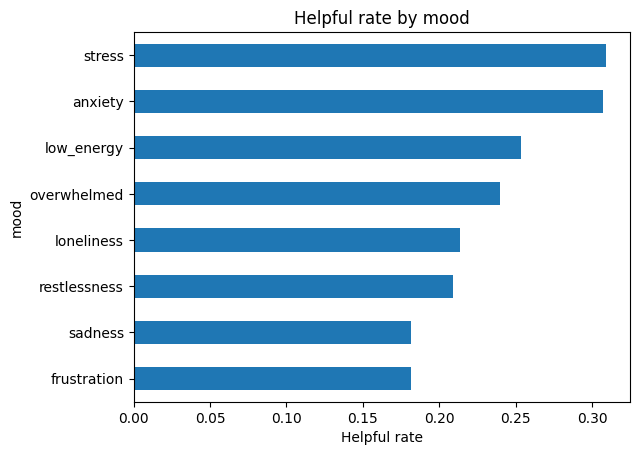

In [12]:
df.groupby("mood")["helpful"].mean().sort_values().plot(kind="barh", title="Helpful rate by mood")
plt.xlabel("Helpful rate")
plt.show()

In [13]:
print("Duplicate rows:", df.duplicated().sum())

Duplicate rows: 0


In [14]:
print("Unknown or blank values:")
for col in df.select_dtypes(include="object").columns:
    print(col, (df[col].isin(["?", "Unknown", ""])).sum())

Unknown or blank values:
interaction_id 0
user_id 0
timestamp 0
day_of_week 0
time_of_day 0
mood 0
activity_id 0
source 0
action 0
split 0
age_group 0
experience_level 0
pref_category_1 0
pref_category_2 0
activity_title 0
activity_category 0
activity_description 0
target_moods 0


In [15]:
print("Mood values:", sorted(df["mood"].unique()))
print("Time of day values:", sorted(df["time_of_day"].unique()))
print("Action values:", sorted(df["action"].unique()))

Mood values: ['anxiety', 'frustration', 'loneliness', 'low_energy', 'overwhelmed', 'restlessness', 'sadness', 'stress']
Time of day values: ['afternoon', 'evening', 'morning', 'night']
Action values: ['completed', 'dropped', 'skipped']


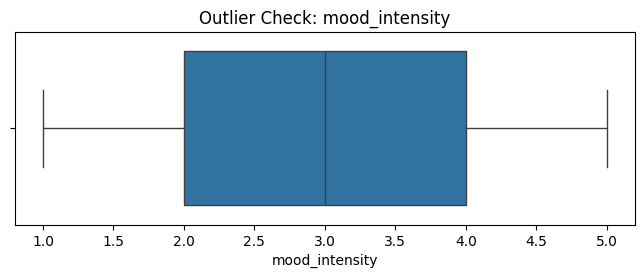

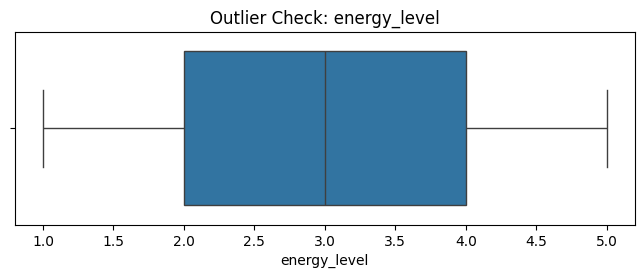

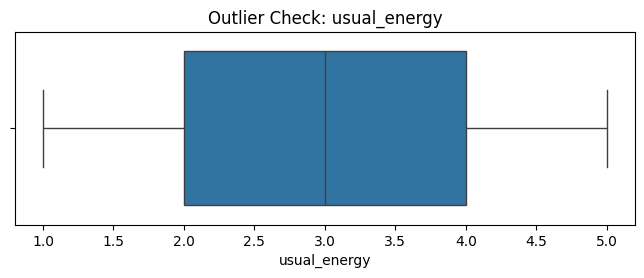

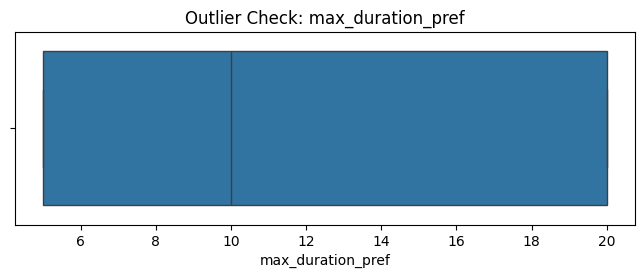

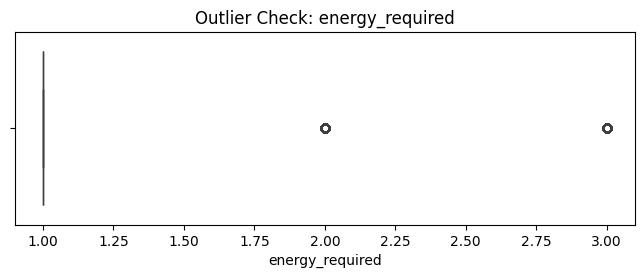

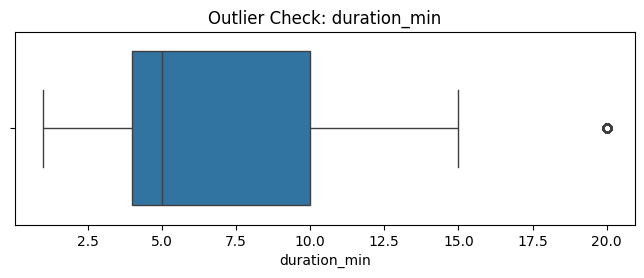

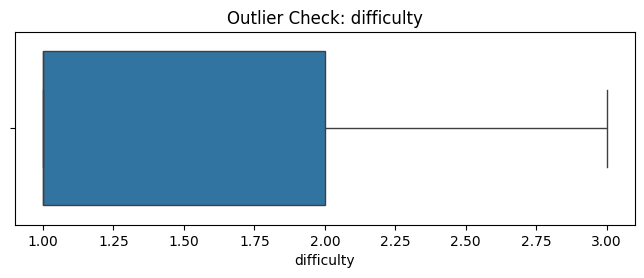

In [16]:
num_check_cols = [
    "mood_intensity", "energy_level", "usual_energy",
    "max_duration_pref", "energy_required", "duration_min", "difficulty"
]
for col in num_check_cols:
    plt.figure(figsize=(8, 2.5))
    sns.boxplot(x=df[col])
    plt.title("Outlier Check: " + col)
    plt.show()

In [17]:
outlier_results = []
for col in num_check_cols:
    q1 = df[col].quantile(0.25)
    q3 = df[col].quantile(0.75)
    iqr = q3 - q1
    lower = q1 - 1.5 * iqr
    upper = q3 + 1.5 * iqr
    count = (
        (df[col] < lower) |
        (df[col] > upper)
    ).sum()
    outlier_results.append({
        "Column": col,
        "Lower Bound": round(lower, 2),
        "Upper Bound": round(upper, 2),
        "Flagged Values": int(count)
    })
outlier_df = pd.DataFrame(outlier_results)
print(outlier_df.to_string(index=False))

           Column  Lower Bound  Upper Bound  Flagged Values
   mood_intensity         -1.0          7.0               0
     energy_level         -1.0          7.0               0
     usual_energy         -1.0          7.0               0
max_duration_pref        -17.5         42.5               0
  energy_required          1.0          1.0            3909
     duration_min         -5.0         19.0            1029
       difficulty         -0.5          3.5               0


energy_required (energy 2-3 wali activities) and duration_min (lambi activities)   asli categories ho skti hai, galat data nahi most pobably

In [18]:
print("Minimum mood intensity:", df["mood_intensity"].min())
print("Maximum mood intensity:", df["mood_intensity"].max())
print("Minimum energy level:", df["energy_level"].min())
print("Maximum energy level:", df["energy_level"].max())

Minimum mood intensity: 1
Maximum mood intensity: 5
Minimum energy level: 1
Maximum energy level: 5


Naye features

In [19]:
print(df.groupby("split")["timestamp"].agg(["min", "max", "count"]))

                    min               max  count
split                                           
test   2026-09-11 00:10  2026-09-28 23:54   3623
train  2026-07-01 00:39  2026-09-11 00:00  14492


In [20]:
df = df.sort_values(["timestamp", "interaction_id"]).reset_index(drop=True)
print(df[["timestamp", "user_id", "mood", "helpful"]].head(3))

          timestamp user_id         mood  helpful
0  2026-07-01 00:39   U0424      anxiety        1
1  2026-07-01 00:43   U0250      anxiety        0
2  2026-07-01 01:34   U0222  frustration        0


checking kaunsi cheezein helpful rate badalti hain.

In [21]:
same_mood = df["target_moods"].str.split(";").str[0] == df["mood"]
print("Activity ka main mood = user ka mood:")
print(df.groupby(same_mood)["helpful"].mean().round(3))

Activity ka main mood = user ka mood:
False    0.14
True     0.50
Name: helpful, dtype: float64


In [22]:
too_long = df["duration_min"] > df["max_duration_pref"]
print("Activity user ke max time se lambi:")
print(df.groupby(too_long)["helpful"].mean().round(3))

Activity user ke max time se lambi:
False    0.278
True     0.086
Name: helpful, dtype: float64


In [23]:
heavy = (df["energy_level"] <= 2) & (df["energy_required"] >= 2)
print("Energy low aur activity heavy:")
print(df.groupby(heavy)["helpful"].mean().round(3))

Energy low aur activity heavy:
False    0.269
True     0.038
Name: helpful, dtype: float64


In [24]:
beginner_hard = (df["experience_level"] == "beginner") & (df["difficulty"] >= 2)
print("Beginner user aur difficult activity:")
print(df.groupby(beginner_hard)["helpful"].mean().round(3))

Beginner user aur difficult activity:
False    0.271
True     0.119
Name: helpful, dtype: float64


In [25]:
first_mood = df["target_moods"].str.split(";").str[0]
df["mood_is_main"] = (first_mood == df["mood"]).astype(int)
df["mood_is_target"] = [int(m in t.split(";")) for m, t in zip(df["mood"], df["target_moods"])]
df["cat_is_pref"] = np.where(
    df["activity_category"] == df["pref_category_1"], 2,
    np.where(df["activity_category"] == df["pref_category_2"], 1, 0)
)
df["too_long"] = (df["duration_min"] > df["max_duration_pref"]).astype(int)
df["heavy_on_low_energy"] = ((df["energy_level"] <= 2) & (df["energy_required"] >= 2)).astype(int)
df["beginner_hard"] = ((df["experience_level"] == "beginner") & (df["difficulty"] >= 2)).astype(int)

In [26]:
new_features = ["mood_is_main", "mood_is_target", "cat_is_pref", "too_long", "heavy_on_low_energy", "beginner_hard"]
print(df[new_features].mean().round(3))

mood_is_main           0.301
mood_is_target         0.681
cat_is_pref            0.332
too_long               0.154
heavy_on_low_energy    0.088
beginner_hard          0.149
dtype: float64


In [27]:
old_part = df[df["split"] == "train"]
new_part = df[df["split"] == "test"]
a = old_part.groupby("user_id")["helpful"].mean()
b = new_part.groupby("user_id")["helpful"].mean()
both = pd.concat([a, b], axis=1, keys=["train", "test"]).dropna()
print("User level correlation:", round(both.corr().iloc[0, 1], 3))

User level correlation: -0.06


In [28]:
a = old_part.groupby(["user_id", "activity_category"])["helpful"].mean()
b = new_part.groupby(["user_id", "activity_category"])["helpful"].mean()
both = pd.concat([a, b], axis=1, keys=["train", "test"]).dropna()
print("User + category correlation:", round(both.corr().iloc[0, 1], 3))

User + category correlation: 0.111


In [29]:
prior = df[df["split"] == "train"]["helpful"].mean()
K = 2
print("Default helpful rate for new users:", round(prior, 3))

Default helpful rate for new users: 0.249


In [30]:
user_group = df.groupby("user_id")
df["user_past_count"] = user_group.cumcount()
df["user_past_rate"] = (
    (user_group["helpful"].cumsum() - df["helpful"]) + prior * K
) / (df["user_past_count"] + K)

In [31]:
user_cat_group = df.groupby(["user_id", "activity_category"])
df["user_cat_past_rate"] = (
    (user_cat_group["helpful"].cumsum() - df["helpful"]) + prior * K
) / (user_cat_group.cumcount() + K)

In [32]:
one_user = df[df["user_id"] == df["user_id"].iloc[0]]
print(one_user[["timestamp", "activity_category", "helpful", "user_past_count", "user_past_rate"]].head(6))

             timestamp activity_category  helpful  user_past_count  \
0     2026-07-01 00:39         grounding        1                0   
318   2026-07-02 17:43        journaling        0                1   
961   2026-07-05 21:03        journaling        0                2   
3180  2026-07-16 22:50          movement        0                3   
3518  2026-07-18 20:09        journaling        0                4   
3812  2026-07-20 07:18          movement        1                5   

      user_past_rate  
0           0.249241  
318         0.499494  
961         0.374620  
3180        0.299696  
3518        0.249747  
3812        0.214069  


In [33]:
cat_cols = [
    "mood", "time_of_day", "age_group", "experience_level",
    "pref_category_1", "pref_category_2", "activity_category"
]
num_cols = [
    "mood_intensity", "energy_level", "usual_energy", "max_duration_pref",
    "energy_required", "duration_min", "difficulty", "needs_privacy",
    "mood_is_main", "mood_is_target", "cat_is_pref", "too_long",
    "heavy_on_low_energy", "beginner_hard",
    "user_past_count", "user_past_rate", "user_cat_past_rate"
]

In [34]:
print("Numerical columns:", num_cols)
print()
print("Categorical columns:", cat_cols)

Numerical columns: ['mood_intensity', 'energy_level', 'usual_energy', 'max_duration_pref', 'energy_required', 'duration_min', 'difficulty', 'needs_privacy', 'mood_is_main', 'mood_is_target', 'cat_is_pref', 'too_long', 'heavy_on_low_energy', 'beginner_hard', 'user_past_count', 'user_past_rate', 'user_cat_past_rate']

Categorical columns: ['mood', 'time_of_day', 'age_group', 'experience_level', 'pref_category_1', 'pref_category_2', 'activity_category']


In [35]:
X = df[cat_cols + num_cols]
y = df["helpful"]
print("Features shape:", X.shape)
print("Target shape:", y.shape)

Features shape: (18115, 24)
Target shape: (18115,)


In [36]:
train_mask = df["split"] == "train"
X_train = X[train_mask].reset_index(drop=True)
y_train = y[train_mask].reset_index(drop=True)
X_test = X[~train_mask].reset_index(drop=True)
y_test = y[~train_mask].reset_index(drop=True)
train_df = df[train_mask].reset_index(drop=True)
test_df = df[~train_mask].reset_index(drop=True)

In [37]:
print("Training rows:", X_train.shape[0])
print("Testing rows:", X_test.shape[0])
print("Train time:", train_df["timestamp"].min(), "to", train_df["timestamp"].max())
print("Test time:", test_df["timestamp"].min(), "to", test_df["timestamp"].max())

Training rows: 14492
Testing rows: 3623
Train time: 2026-07-01 00:39 to 2026-09-11 00:00
Test time: 2026-09-11 00:10 to 2026-09-28 23:54


In [38]:
from sklearn.model_selection import TimeSeriesSplit, cross_validate
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.base import clone

In [39]:
tscv = TimeSeriesSplit(n_splits=4)
fold_rows = []
fold_number = 1
for train_idx, val_idx in tscv.split(X_train):
    fold_rows.append({
        "Fold": fold_number,
        "Train rows": len(train_idx),
        "Validation rows": len(val_idx),
        "Validation from": train_df.loc[val_idx[0], "timestamp"],
        "Validation to": train_df.loc[val_idx[-1], "timestamp"],
        "Helpful rate (%)": round(y_train.iloc[val_idx].mean() * 100, 2)
    })
    fold_number = fold_number + 1
print(pd.DataFrame(fold_rows).to_string(index=False))

 Fold  Train rows  Validation rows  Validation from    Validation to  Helpful rate (%)
    1        2900             2898 2026-07-15 17:32 2026-07-30 11:53             24.50
    2        5798             2898 2026-07-30 11:53 2026-08-13 19:58             25.74
    3        8696             2898 2026-08-13 20:07 2026-08-27 20:39             24.40
    4       11594             2898 2026-08-27 20:44 2026-09-11 00:00             23.81


In [40]:
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier, export_text, plot_tree
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression

In [41]:
from sklearn.metrics import confusion_matrix, classification_report, roc_curve, roc_auc_score
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

In [42]:
preprocessor = ColumnTransformer([
    ("num", StandardScaler(), num_cols),
    ("cat", OneHotEncoder(handle_unknown="ignore"), cat_cols)
])

In [43]:
print("Unique values in categorical columns:")
print(X_train[cat_cols].nunique())
print()
print(X_train[num_cols].agg(["min", "max"]).T)

Unique values in categorical columns:
mood                 8
time_of_day          4
age_group            4
experience_level     2
pref_category_1      9
pref_category_2      9
activity_category    9
dtype: int64

                          min         max
mood_intensity       1.000000    5.000000
energy_level         1.000000    5.000000
usual_energy         1.000000    5.000000
max_duration_pref    5.000000   20.000000
energy_required      1.000000    3.000000
duration_min         1.000000   20.000000
difficulty           1.000000    3.000000
needs_privacy        0.000000    1.000000
mood_is_main         0.000000    1.000000
mood_is_target       0.000000    1.000000
cat_is_pref          0.000000    2.000000
too_long             0.000000    1.000000
heavy_on_low_energy  0.000000    1.000000
beginner_hard        0.000000    1.000000
user_past_count      0.000000  151.000000
user_past_rate       0.019939    0.849848
user_cat_past_rate   0.031155    0.849848


In [44]:
seed_aucs = []
for seed in [1, 2, 3, 4, 5]:
    pipeline = Pipeline([
        ("preprocessing", preprocessor),
        ("model", RandomForestClassifier(
            n_estimators=100,
            class_weight="balanced_subsample",
            random_state=seed,
            n_jobs=-1
        ))
    ])
    scores = cross_validate(pipeline, X_train, y_train, cv=tscv, scoring="roc_auc")
    seed_aucs.append(float(round(scores["test_score"].mean() * 100, 2)))
print("Validation AUC (%) with different seeds:", seed_aucs)

Validation AUC (%) with different seeds: [83.41, 83.39, 83.38, 83.44, 83.5]


In [45]:
noise = round(max(seed_aucs) - min(seed_aucs), 2)
tolerance = max(noise, 0.10)
print("Noise (max - min):", noise)
print("Tolerance used from now on:", tolerance)

Noise (max - min): 0.12
Tolerance used from now on: 0.12


In [46]:
scaler_results = []
for name, scaler in [("With StandardScaler", StandardScaler()), ("Without StandardScaler", "passthrough")]:
    pipeline = Pipeline([
        ("preprocessing", ColumnTransformer([
            ("num", scaler, num_cols),
            ("cat", OneHotEncoder(handle_unknown="ignore"), cat_cols)
        ])),
        ("model", LogisticRegression(max_iter=2000, random_state=42))
    ])
    scores = cross_validate(pipeline, X_train, y_train, cv=tscv, scoring="roc_auc")
    scaler_results.append({"Setting": name, "Validation AUC (%)": round(scores["test_score"].mean() * 100, 2)})
print(pd.DataFrame(scaler_results).to_string(index=False))

               Setting  Validation AUC (%)
   With StandardScaler               84.61
Without StandardScaler               84.62


In [47]:
from sklearn.preprocessing import OrdinalEncoder
encoder_results = []
for name, encoder in [
    ("OneHotEncoder", OneHotEncoder(handle_unknown="ignore")),
    ("OrdinalEncoder", OrdinalEncoder(handle_unknown="use_encoded_value", unknown_value=-1))
]:
    pipeline = Pipeline([
        ("preprocessing", ColumnTransformer([
            ("num", StandardScaler(), num_cols),
            ("cat", encoder, cat_cols)
        ])),
        ("model", LogisticRegression(max_iter=2000, random_state=42))
    ])
    scores = cross_validate(pipeline, X_train, y_train, cv=tscv, scoring="roc_auc")
    encoder_results.append({"Setting": name, "Validation AUC (%)": round(scores["test_score"].mean() * 100, 2)})
print(pd.DataFrame(encoder_results).to_string(index=False))

       Setting  Validation AUC (%)
 OneHotEncoder               84.61
OrdinalEncoder               84.67


In [48]:
base_pipeline = Pipeline([
    ("preprocessing", preprocessor),
    ("model", LogisticRegression(max_iter=2000, random_state=42))
])
fold_check_results = []
for n in [3, 4, 5, 6]:
    scores = cross_validate(base_pipeline, X_train, y_train, cv=TimeSeriesSplit(n_splits=n), scoring="roc_auc")
    fold_check_results.append({"Folds": n, "Validation AUC (%)": round(scores["test_score"].mean() * 100, 2)})
print(pd.DataFrame(fold_check_results).to_string(index=False))

 Folds  Validation AUC (%)
     3               84.41
     4               84.61
     5               84.51
     6               84.54


In [49]:
base_feature_pipeline = Pipeline([
    ("preprocessing", preprocessor),
    ("model", LogisticRegression(max_iter=2000, random_state=42))
])
scores = cross_validate(base_feature_pipeline, X_train, y_train, cv=tscv, scoring="roc_auc")
base_feature_auc = round(scores["test_score"].mean() * 100, 2)
print("Validation AUC (%) with all features:", base_feature_auc)
print("Tolerance:", tolerance)

Validation AUC (%) with all features: 84.61
Tolerance: 0.12


In [50]:
check_features = [
    "mood_is_main", "mood_is_target", "cat_is_pref", "too_long",
    "heavy_on_low_energy", "beginner_hard",
    "user_past_count", "user_past_rate", "user_cat_past_rate"
]
feature_drop_results = []
for feature in check_features:
    num_list = [c for c in num_cols if c != feature]
    pipeline = Pipeline([
        ("preprocessing", ColumnTransformer([
            ("num", StandardScaler(), num_list),
            ("cat", OneHotEncoder(handle_unknown="ignore"), cat_cols)
        ])),
        ("model", LogisticRegression(max_iter=2000, random_state=42))
    ])
    scores = cross_validate(pipeline, X_train[cat_cols + num_list], y_train, cv=tscv, scoring="roc_auc")
    auc_without = round(scores["test_score"].mean() * 100, 2)
    feature_drop_results.append({
        "Feature": feature,
        "AUC without it (%)": auc_without,
        "AUC drop (%)": round(base_feature_auc - auc_without, 2)
    })
feature_drop_df = pd.DataFrame(feature_drop_results).sort_values("AUC drop (%)", ascending=False)
print(feature_drop_df.to_string(index=False))

            Feature  AUC without it (%)  AUC drop (%)
     mood_is_target               80.79          3.82
       mood_is_main               81.70          2.91
        cat_is_pref               83.02          1.59
           too_long               84.04          0.57
heavy_on_low_energy               84.20          0.41
      beginner_hard               84.43          0.18
     user_past_rate               84.62         -0.01
 user_cat_past_rate               84.62         -0.01
    user_past_count               84.68         -0.07


Pehle 6 features ke hatane se AUC tolerance se zyada girta hai (0.18 se 3.82), isliye woh sab zaroori hain. Past feedback wale 3 features ka asar lagbhag zero hai.

In [51]:
past_features = ["user_past_count", "user_past_rate", "user_cat_past_rate"]
num_list = [c for c in num_cols if c not in past_features]
pipeline = Pipeline([
    ("preprocessing", ColumnTransformer([
        ("num", StandardScaler(), num_list),
        ("cat", OneHotEncoder(handle_unknown="ignore"), cat_cols)
    ])),
    ("model", LogisticRegression(max_iter=2000, random_state=42))
])
scores = cross_validate(pipeline, X_train[cat_cols + num_list], y_train, cv=tscv, scoring="roc_auc")
print("Validation AUC (%) with past feedback features:", base_feature_auc)
print("Validation AUC (%) without all 3 past feedback features:", round(scores["test_score"].mean() * 100, 2))

Validation AUC (%) with past feedback features: 84.61
Validation AUC (%) without all 3 past feedback features: 84.69


In [52]:
k_results = []
for k_value in [1, 2, 5, 10, 20, 50]:
    temp_df = df.copy()
    temp_group = temp_df.groupby("user_id")
    temp_df["user_past_count"] = temp_group.cumcount()
    temp_df["user_past_rate"] = (
        (temp_group["helpful"].cumsum() - temp_df["helpful"]) + prior * k_value
    ) / (temp_df["user_past_count"] + k_value)
    temp_cat_group = temp_df.groupby(["user_id", "activity_category"])
    temp_df["user_cat_past_rate"] = (
        (temp_cat_group["helpful"].cumsum() - temp_df["helpful"]) + prior * k_value
    ) / (temp_cat_group.cumcount() + k_value)
    X_temp = temp_df[train_mask][cat_cols + num_cols].reset_index(drop=True)
    scores = cross_validate(base_feature_pipeline, X_temp, y_train, cv=tscv, scoring="roc_auc")
    k_results.append({"K": k_value, "Validation AUC (%)": round(scores["test_score"].mean() * 100, 2)})
print(pd.DataFrame(k_results).to_string(index=False))

 K  Validation AUC (%)
 1               84.61
 2               84.61
 5               84.62
10               84.62
20               84.61
50               84.61


K badalne se AUC nahi badla (84.61 se 84.62). K = 2 theek hai.

ML model se pehle 2 simple baselines dekhte hain. ML ko inse behtar hona chahiye.

In [54]:
from google.colab import files
uploaded = files.upload()

Saving mood_activity_rules.csv to mood_activity_rules.csv


In [55]:
rules = pd.read_csv("mood_activity_rules.csv")
print(rules.head(6))

      mood  priority     category
0   stress         1    breathing
1   stress         2  mindfulness
2   stress         3     movement
3  anxiety         1    grounding
4  anxiety         2    breathing
5  anxiety         3  mindfulness


In [56]:
val_rows = np.concatenate([val_idx for train_idx, val_idx in tscv.split(X_train)])
y_val_rows = y_train.iloc[val_rows]
print("Total validation rows:", len(val_rows))

Total validation rows: 11592


In [57]:
rule_train = train_df.merge(
    rules,
    left_on=["mood", "activity_category"],
    right_on=["mood", "category"],
    how="left"
)
rule_pred = (rule_train["priority"] == 1).astype(int).iloc[val_rows]
print("Rows where activity was priority-1 category:", round(rule_pred.mean() * 100, 2), "%")

Rows where activity was priority-1 category: 30.09 %


In [58]:
baseline_results = []
baseline_predictions = {
    "Always 0": np.zeros(len(y_val_rows), dtype=int),
    "Rule-based (priority 1)": rule_pred.values
}
for name, y_pred in baseline_predictions.items():
    baseline_results.append({
        "Model": name,
        "Accuracy (%)": round(accuracy_score(y_val_rows, y_pred) * 100, 2),
        "Precision (%)": round(precision_score(y_val_rows, y_pred, zero_division=0) * 100, 2),
        "Recall (%)": round(recall_score(y_val_rows, y_pred, zero_division=0) * 100, 2),
        "F1 Score (%)": round(f1_score(y_val_rows, y_pred, zero_division=0) * 100, 2)
    })
baseline_df = pd.DataFrame(baseline_results)
print(baseline_df.to_string(index=False))

                  Model  Accuracy (%)  Precision (%)  Recall (%)  F1 Score (%)
               Always 0         75.39           0.00        0.00          0.00
Rule-based (priority 1)         66.93          35.95       43.95         39.55


'Always 0' ki accuracy zyada hai par precision aur recall 0 hain. Isliye sirf accuracy par bharosa nahi karenge.

